## Configuración

In [1]:
import json, sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sys.path.insert(0, str(next(p / "src" for p in [Path.cwd(), *Path.cwd().resolve().parents] if (p / "src").is_dir())))
from data_preprocessing import (CLUSTER_FEATURES, DEMOGRAPHIC_COLS, EXTERNAL_COLS, ID_COL, STRESS_ORDER,
                                find_project_root, iqr_outliers, load_data, near_constant, quality_summary)
from clustering import SEED, N_INIT, bootstrap_stability, evaluate_k_range, fit_kmeans, k_votes, null_silhouette, seed_stability
from evaluation import cluster_sizes, cramers_v, eta_squared, vif_table

ROOT = find_project_root()
FIG_DIR, RES_DIR, MODEL_DIR, PROC_DIR = (ROOT / p for p in ("reports/figures", "reports/results", "models", "data/processed"))
for d in (FIG_DIR, RES_DIR, MODEL_DIR, PROC_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
np.random.seed(SEED)

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")
print(f"Semilla = {SEED} | n_init = {N_INIT}")

Python 3.12.3 | pandas 3.0.2 | numpy 2.4.4 | scikit-learn 1.8.0
Semilla = 100 | n_init = 20


## Datos

In [2]:
raw = load_data()
print("Dimensiones:", raw.shape)
display(raw.head(8))
display(quality_summary(raw))

Dimensiones: (1512, 12)


,student_id,study_hours,sleep_hours,social_hours,physical_activity_hours,screen_time_hours,extracurricular_hours,gpa,stress_score,stress_level,age,field_of_study
0,1,5.4,5.3,5.6,0.8,6.3,1.3,2.69,7.6,High,22,Engineering
1,2,7.5,4.8,1.3,0.6,4.2,0.9,3.54,8.7,High,23,Health
2,3,4.0,5.7,4.7,1.6,5.4,0.2,2.92,5.0,Moderate,20,Sciences
3,4,7.5,5.7,0.5,0.9,1.5,0.9,3.36,9.8,High,25,Engineering
4,5,6.8,6.0,2.0,1.6,1.8,1.1,3.30,3.4,Low,23,Sciences
5,6,6.4,6.8,0.3,1.1,2.1,0.6,3.32,7.7,High,25,Health
6,7,9.2,4.6,2.0,0.2,3.4,1.0,3.10,8.3,High,19,Engineering
7,8,3.4,7.1,3.8,2.0,5.8,0.0,2.30,4.8,Moderate,19,Business


,dtype,nulos,nulos_%,unicos,min,max
student_id,int64,0,0.00,1512,1.0,1512.0
study_hours,float64,0,0.00,110,0.0,14.0
sleep_hours,float64,30,1.98,60,3.4,9.7
social_hours,float64,0,0.00,73,0.0,7.6
physical_activity_hours,float64,0,0.00,34,0.0,3.6
screen_time_hours,float64,30,1.98,93,0.5,12.0
extracurricular_hours,float64,0,0.00,35,0.0,3.4
gpa,float64,0,0.00,193,1.8,4.0
stress_score,float64,0,0.00,89,0.5,10.0
stress_level,str,0,0.00,3,NaN,NaN


## Exploración

In [3]:
display(raw[CLUSTER_FEATURES + ["gpa", "stress_score"]].describe().round(2).T)
print(raw["stress_level"].value_counts().reindex(STRESS_ORDER).to_frame("n").assign(**{"%": lambda t: (100 * t["n"] / t["n"].sum()).round(1)}))
print()
print(raw["field_of_study"].value_counts().to_frame("n"))

,count,mean,std,min,25%,50%,75%,max
study_hours,1512.0,5.73,2.37,0.0,4.00,5.50,7.70,14.0
sleep_hours,1482.0,6.68,1.16,3.4,5.80,6.80,7.50,9.7
social_hours,1512.0,2.61,1.57,0.0,1.30,2.40,3.72,7.6
physical_activity_hours,1512.0,1.07,0.68,0.0,0.50,1.00,1.60,3.6
screen_time_hours,1482.0,3.84,1.92,0.5,2.50,3.30,4.90,12.0
extracurricular_hours,1512.0,1.19,0.68,0.0,0.70,1.20,1.60,3.4
gpa,1512.0,3.08,0.44,1.8,2.77,3.14,3.39,4.0
stress_score,1512.0,5.60,1.93,0.5,4.10,5.40,7.10,10.0


                n     %
stress_level           
Low           237  15.7
Moderate      782  51.7
High          493  32.6

                  n
field_of_study     
Engineering     365
Business        363
Health          309
Humanities      238
Sciences        237


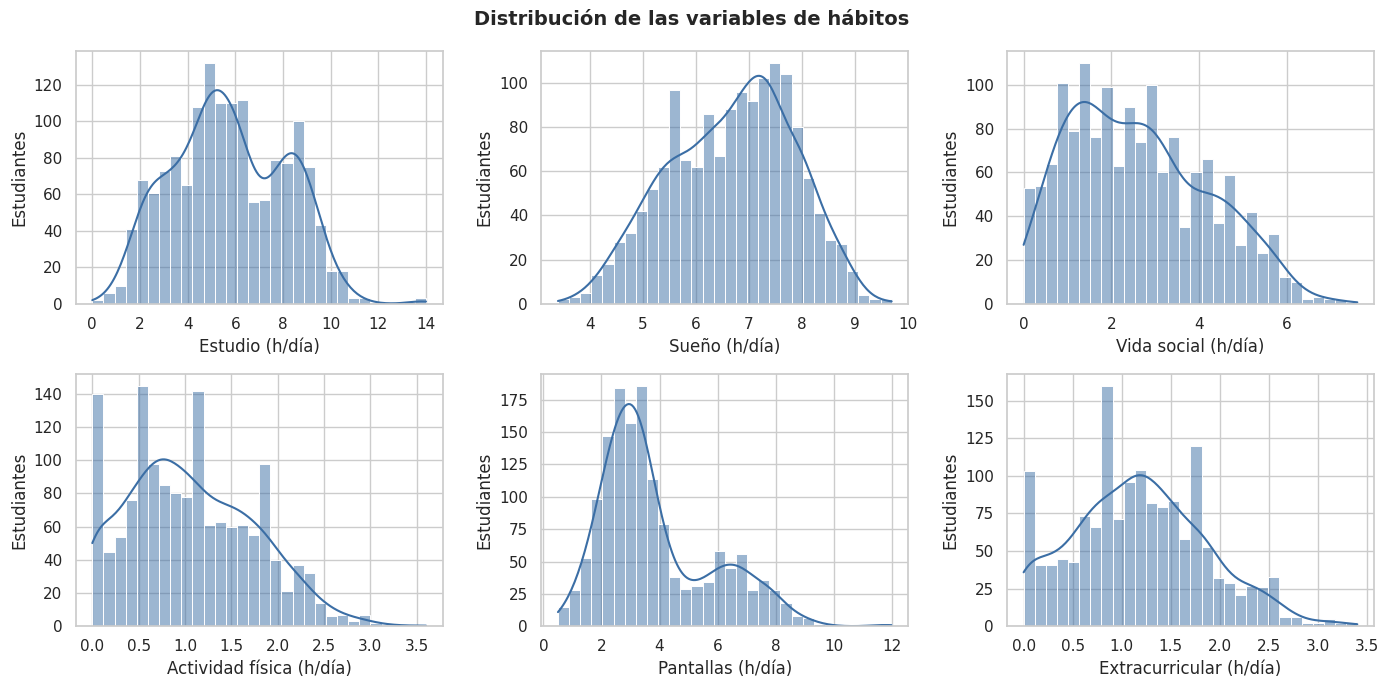

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
labels = ["Estudio (h/día)", "Sueño (h/día)", "Vida social (h/día)", "Actividad física (h/día)", "Pantallas (h/día)", "Extracurricular (h/día)"]
for ax, c, lab in zip(axes.ravel(), CLUSTER_FEATURES, labels):
    sns.histplot(raw[c], bins=30, kde=True, ax=ax, color="#3b6ea5")
    ax.set_xlabel(lab); ax.set_ylabel("Estudiantes")
fig.suptitle("Distribución de las variables de hábitos", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "01_distribuciones.png")
plt.show()

Estudio y pantallas tienen dos picos (hacia 5 y 8,5 h, y hacia 3 y 6,5 h), así que ya se intuyen subgrupos.

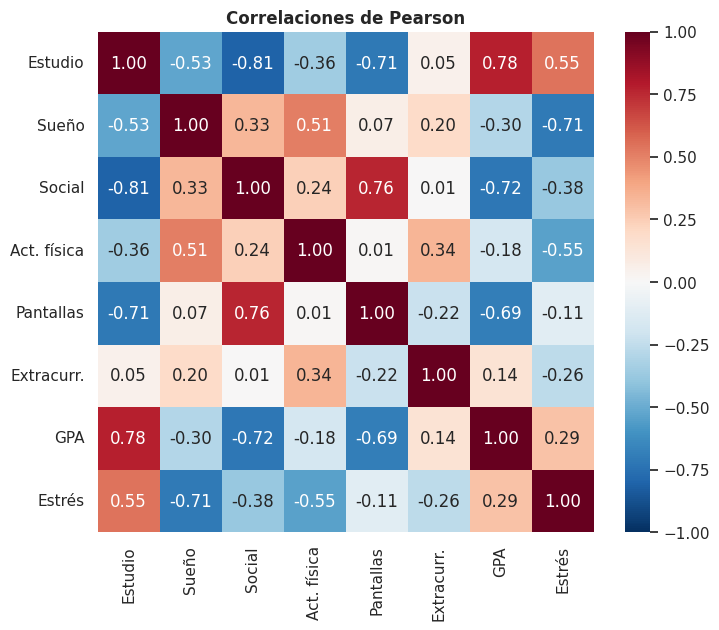

In [5]:
short = dict(zip(CLUSTER_FEATURES + ["gpa", "stress_score"], ["Estudio", "Sueño", "Social", "Act. física", "Pantallas", "Extracurr.", "GPA", "Estrés"]))
corr = raw[CLUSTER_FEATURES + ["gpa", "stress_score"]].corr().rename(index=short, columns=short)
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlaciones de Pearson")
save_fig(fig, "02_correlaciones.png")
plt.show()

Los hábitos están muy correlacionados (estudio con vida social −0,81, vida social con pantallas 0,75). Buena parte viene de que hay grupos distintos, no de que midan lo mismo.

## Limpieza

In [6]:
key_cols = [c for c in raw.columns if c != ID_COL]
print("Filas duplicadas ignorando student_id:", int(raw.duplicated(subset=key_cols).sum()))
print("Nulos por columna:"); print(raw.isna().sum()[lambda s: s > 0].to_string())
print("\nProporción del valor más frecuente:"); print(near_constant(raw, CLUSTER_FEATURES).round(3).to_string())
flags = iqr_outliers(raw, CLUSTER_FEATURES)
print("\nValores fuera de 1.5*IQR:"); print(flags.sum().to_string())
display(raw.loc[flags.any(axis=1), [ID_COL] + CLUSTER_FEATURES])

df = raw.drop_duplicates(subset=key_cols).reset_index(drop=True)
print("\nFilas tras eliminar duplicados:", len(df))

Filas duplicadas ignorando student_id: 12
Nulos por columna:
sleep_hours          30
screen_time_hours    30

Proporción del valor más frecuente:
study_hours                0.022
sleep_hours                0.046
social_hours               0.032
physical_activity_hours    0.065
screen_time_hours          0.037
extracurricular_hours      0.069

Valores fuera de 1.5*IQR:
study_hours                 4
sleep_hours                 0
social_hours                1
physical_activity_hours     2
screen_time_hours          20
extracurricular_hours      12


,student_id,study_hours,sleep_hours,social_hours,physical_activity_hours,screen_time_hours,extracurricular_hours
75,76,5.6,5.6,2.2,1.1,4.6,3.1
87,88,4.9,7.2,3.8,1.4,3.5,3.4
158,159,4.8,8.0,2.9,1.9,1.8,3.2
237,238,2.3,7.1,4.4,1.8,8.9,0.4
322,323,3.7,5.7,4.8,1.5,8.8,1.4
358,359,1.2,6.3,5.4,0.5,11.5,1.6
387,388,5.6,6.6,2.0,1.5,2.6,3.1
390,391,2.0,6.5,7.6,0.7,7.3,0.9
408,409,14.0,5.4,0.8,1.1,3.2,0.4
462,463,6.0,7.4,3.4,1.3,3.5,3.1



Filas tras eliminar duplicados: 1500


Hay 12 filas repetidas, que quito, y 30 nulos en sueño y otros 30 en pantallas, que relleno con la mediana dentro del pipeline. El IQR marca 38 filas extremas (sobre todo pantallas y extracurriculares). Son valores posibles y las dejo; más adelante compruebo que no cambian el resultado.

## Variables

In [7]:
print("Variables para formar clusters:", CLUSTER_FEATURES)
print("Variables reservadas para interpretación:", EXTERNAL_COLS)
print("Variables demográficas excluidas:", DEMOGRAPHIC_COLS, "| identificador excluido:", ID_COL)
print()
print("VIF de las variables de clustering (imputación por mediana):")
Xi = pd.DataFrame(SimpleImputer(strategy="median").fit_transform(df[CLUSTER_FEATURES]), columns=CLUSTER_FEATURES)
display(vif_table(Xi).round(2).to_frame())
upper = Xi.corr().where(np.triu(np.ones((6, 6), bool), 1)).stack()
print("Pares con |r| > 0.2:")
print(upper[upper.abs() > 0.2].round(2).to_string())

Variables para formar clusters: ['study_hours', 'sleep_hours', 'social_hours', 'physical_activity_hours', 'screen_time_hours', 'extracurricular_hours']
Variables reservadas para interpretación: ['gpa', 'stress_score', 'stress_level']
Variables demográficas excluidas: ['age', 'field_of_study'] | identificador excluido: student_id

VIF de las variables de clustering (imputación por mediana):


,VIF
study_hours,4.98
sleep_hours,1.99
social_hours,3.71
physical_activity_hours,1.57
screen_time_hours,3.42
extracurricular_hours,1.26


Pares con |r| > 0.2:
study_hours              sleep_hours               -0.52
                         social_hours              -0.81
                         physical_activity_hours   -0.36
                         screen_time_hours         -0.71
sleep_hours              social_hours               0.33
                         physical_activity_hours    0.51
social_hours             physical_activity_hours    0.24
                         screen_time_hours          0.75
physical_activity_hours  extracurricular_hours      0.34
screen_time_hours        extracurricular_hours     -0.22


In [8]:
core = ["study_hours", "sleep_hours", "social_hours", "screen_time_hours"]
rows, parts = [], {}
for name, cols in {"6 variables": CLUSTER_FEATURES, "4 variables (sin act. física ni extracurricular)": core}.items():
    Xs = StandardScaler().fit_transform(Xi[cols])
    m = evaluate_k_range(Xs, range(2, 8))
    parts[name] = fit_kmeans(Xs, 3).labels_
    rows.append({"conjunto": name, "K por silhouette": int(m["silhouette"].idxmax()), "K por Davies-Bouldin": int(m["davies_bouldin"].idxmin()),
                 "K por Calinski-Harabasz": int(m["calinski_harabasz"].idxmax()), "silhouette en K=3": m.loc[3, "silhouette"]})
display(pd.DataFrame(rows).set_index("conjunto").round(3))
a, b = parts.values()
print("ARI entre las particiones K=3 de ambos conjuntos:", round(adjusted_rand_score(a, b), 3))

,K por silhouette,K por Davies-Bouldin,K por Calinski-Harabasz,silhouette en K=3
conjunto,,,,
6 variables,3,3,3,0.365
4 variables (sin act. física ni extracurricular),3,3,3,0.456


ARI entre las particiones K=3 de ambos conjuntos: 0.832


Uso las seis variables de hábitos. El VIF más alto es 4,98 (estudio), así que ninguna es redundante. Con solo cuatro variables la partición cambia bastante (ARI 0,83) y se pierden actividad física y extracurriculares, por eso las mantengo. GPA, estrés, edad y área de estudio quedan fuera del clustering.

## Estandarización

In [9]:
prep = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())])
X = prep.fit_transform(df[CLUSTER_FEATURES])
X_orig = pd.DataFrame(prep.named_steps["impute"].transform(df[CLUSTER_FEATURES]), columns=CLUSTER_FEATURES, index=df.index)
print("Desviación estándar antes de estandarizar (horas):")
print(X_orig.std().round(2).to_string())
print("\nMedia y desviación tras estandarizar:", X.mean(axis=0).round(6), X.std(axis=0).round(6))
unscaled = fit_kmeans(X_orig.to_numpy(), 3).labels_
print("ARI K=3 estandarizado vs sin estandarizar:", round(adjusted_rand_score(fit_kmeans(X, 3).labels_, unscaled), 3))

Desviación estándar antes de estandarizar (horas):
study_hours                2.36
sleep_hours                1.15
social_hours               1.57
physical_activity_hours    0.68
screen_time_hours          1.90
extracurricular_hours      0.68

Media y desviación tras estandarizar: [ 0.  0. -0. -0.  0. -0.] [1. 1. 1. 1. 1. 1.]
ARI K=3 estandarizado vs sin estandarizar: 0.859


Las desviaciones van de 0,68 a 2,36 horas, así que estandarizo; sin hacerlo la partición cambia (ARI 0,86).

## Elección de K

In [10]:
K_RANGE = list(range(2, 11))
metrics = evaluate_k_range(X, K_RANGE)
null = null_silhouette(X, K_RANGE, n_null=30)
metrics["silhouette_nula_media"] = null.mean()
metrics["silhouette_nula_max"] = null.max()
display(metrics.round(3))
votes = k_votes(metrics)
display(votes.to_frame("K sugerido"))
K_FINAL = int(votes.mode().iloc[0])
print("K elegido por mayoría de criterios:", K_FINAL, f"({int((votes == K_FINAL).sum())} de {len(votes)} criterios)")
metrics.round(4).to_csv(RES_DIR / "k_selection_metrics.csv")
votes.to_csv(RES_DIR / "k_votes.csv", header=["k"])

,inercia,silhouette,davies_bouldin,calinski_harabasz,cluster_min_%,cluster_max_%,silhouette_nula_media,silhouette_nula_max
k,,,,,,,,
2,5776.645,0.327,1.140,835.881,34.600,65.400,0.148,0.167
3,3834.723,0.365,1.075,1008.211,27.200,39.467,0.135,0.140
4,3411.687,0.281,1.337,816.811,20.067,31.067,0.131,0.136
5,3153.040,0.235,1.483,693.078,15.533,25.667,0.129,0.137
6,2948.506,0.199,1.719,613.255,12.333,21.933,0.130,0.138
7,2766.419,0.186,1.714,560.697,10.867,17.733,0.131,0.136
8,2637.824,0.184,1.654,514.080,8.333,17.133,0.132,0.137
9,2513.947,0.177,1.629,480.859,7.933,15.800,0.133,0.138
10,2398.250,0.178,1.581,455.731,8.067,12.933,0.133,0.144


,K sugerido
"codo, distancia a la cuerda",4
"codo, máxima curvatura",3
silhouette (máximo),3
Davies-Bouldin (mínimo),3
Calinski-Harabasz (máximo),3


K elegido por mayoría de criterios: 3 (4 de 5 criterios)


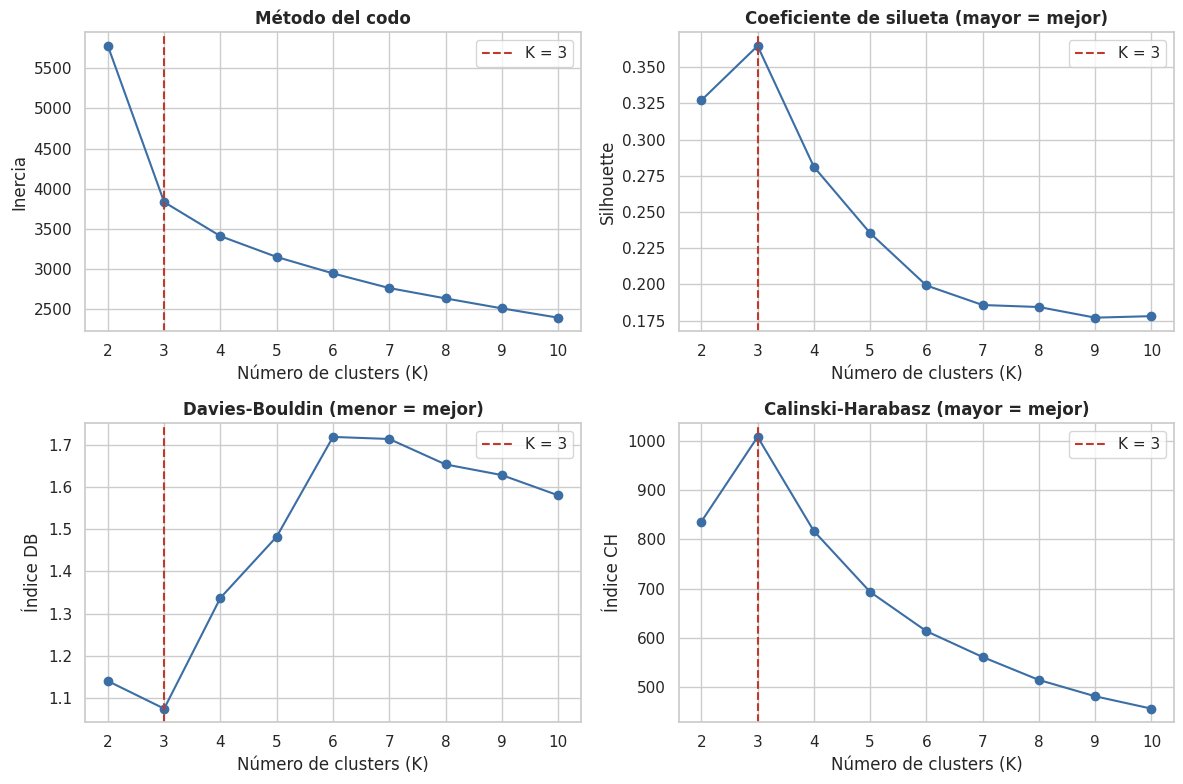

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
specs = [("inercia", "Método del codo", "Inercia"), ("silhouette", "Coeficiente de silueta (mayor = mejor)", "Silhouette"),
         ("davies_bouldin", "Davies-Bouldin (menor = mejor)", "Índice DB"), ("calinski_harabasz", "Calinski-Harabasz (mayor = mejor)", "Índice CH")]
for ax, (col, title, yl) in zip(axes.ravel(), specs):
    ax.plot(K_RANGE, metrics[col], "o-", color="#3b6ea5")
    ax.axvline(K_FINAL, color="#c0392b", ls="--", label=f"K = {K_FINAL}")
    ax.set(title=title, xlabel="Número de clusters (K)", ylabel=yl)
    ax.legend()
fig.tight_layout()
save_fig(fig, "03_metricas_k.png")
plt.show()

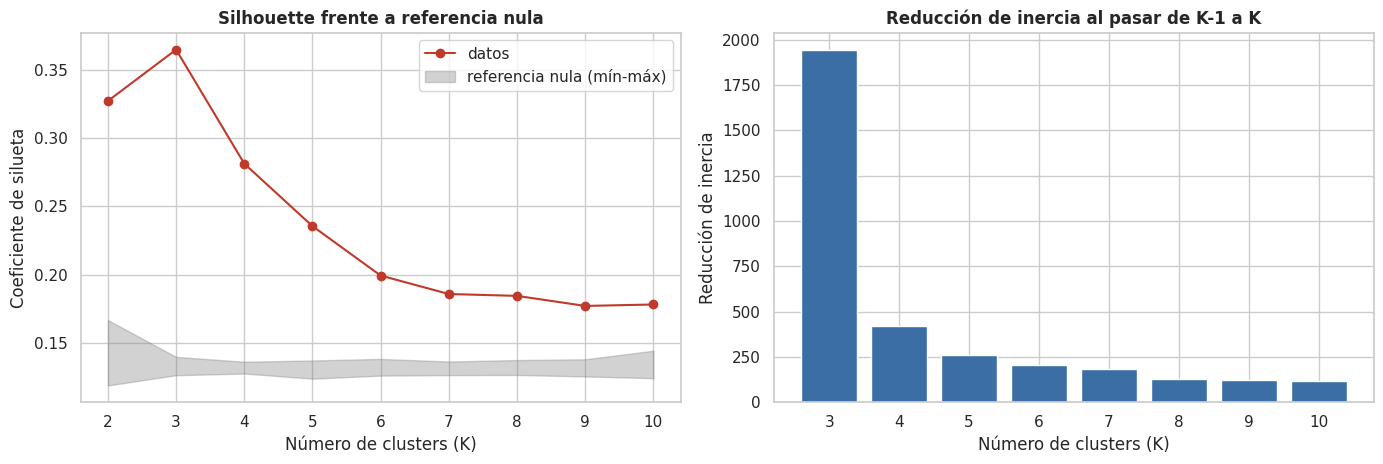

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(K_RANGE, metrics["silhouette"], "o-", color="#c0392b", label="datos")
axes[0].fill_between(K_RANGE, null.min(), null.max(), color="gray", alpha=0.35, label="referencia nula (mín-máx)")
axes[0].set(title="Silhouette frente a referencia nula", xlabel="Número de clusters (K)", ylabel="Coeficiente de silueta")
axes[0].legend()
d1 = -np.diff(metrics["inercia"].to_numpy())
axes[1].bar(K_RANGE[1:], d1, color="#3b6ea5")
axes[1].set(title="Reducción de inercia al pasar de K-1 a K", xlabel="Número de clusters (K)", ylabel="Reducción de inercia")
fig.tight_layout()
save_fig(fig, "04_silhouette_nula_y_reduccion_inercia.png")
plt.show()

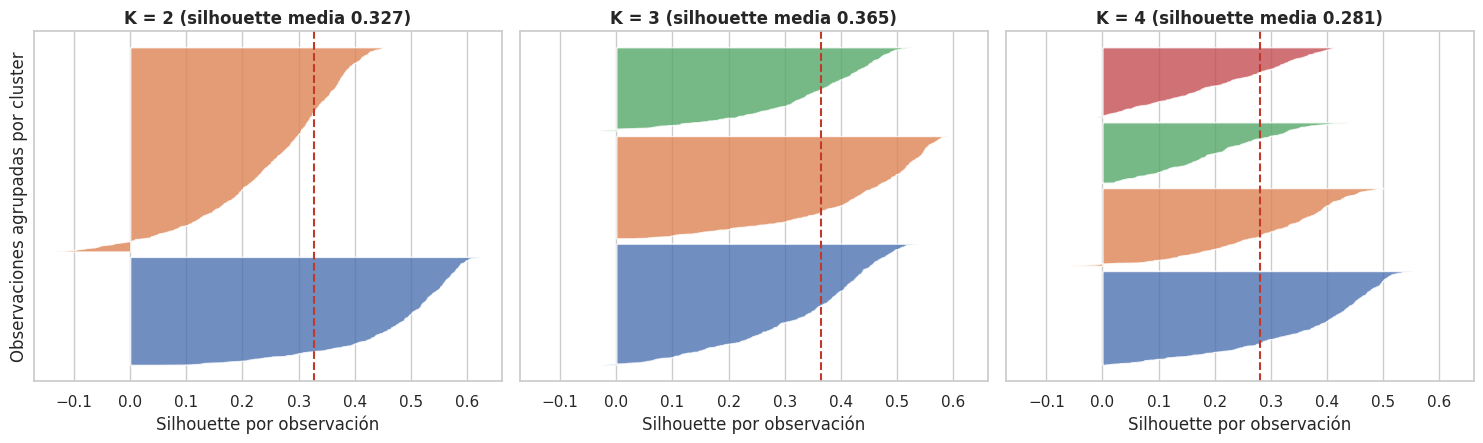

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), sharex=True)
for ax, k in zip(axes, (2, 3, 4)):
    lab = fit_kmeans(X, k).labels_
    s = silhouette_samples(X, lab)
    y0 = 0
    for c in range(k):
        sc = np.sort(s[lab == c])
        ax.fill_betweenx(np.arange(y0, y0 + len(sc)), 0, sc, alpha=0.8)
        y0 += len(sc) + 25
    ax.axvline(s.mean(), color="#c0392b", ls="--")
    ax.set(title=f"K = {k} (silhouette media {s.mean():.3f})", xlabel="Silhouette por observación", yticks=[])
axes[0].set_ylabel("Observaciones agrupadas por cluster")
fig.tight_layout()
save_fig(fig, "05_silhouette_por_observacion.png")
plt.show()

Cuatro de los cinco criterios dan K = 3: silhouette (0,365), Davies-Bouldin (1,075), Calinski-Harabasz (1 008) y el codo por curvatura. El codo por distancia a la cuerda da 4, pero la inercia cae 1 942 entre K = 2 y 3 y solo 423 entre 3 y 4.

La silhouette de K = 3 está muy por encima de la de los datos con las columnas mezcladas al azar (0,135). En el gráfico por observación, casi todos los puntos de los tres clusters tienen silueta positiva; con K = 2 hay negativos en el cluster grande y con K = 4 dos clusters quedan por debajo de la media.

## Modelo final

In [14]:
km_raw = fit_kmeans(X, K_FINAL)
order = X_orig.groupby(km_raw.labels_)["study_hours"].mean().sort_values(ascending=False).index.tolist()
letters = dict(zip(order, "ABCDEFGH"[:K_FINAL]))
labels = pd.Series(km_raw.labels_).map(letters).to_numpy()
df["cluster"] = labels

print("Inercia:", round(km_raw.inertia_, 1), "| iteraciones:", km_raw.n_iter_, "| silhouette:", round(silhouette_score(X, labels), 3))
display(cluster_sizes(labels))

joblib.dump(prep, MODEL_DIR / "preprocessor.joblib")
joblib.dump(km_raw, MODEL_DIR / "kmeans_final.joblib")
_ = (MODEL_DIR / "label_mapping.json").write_text(json.dumps({"kmeans_label_to_profile": {str(k): v for k, v in letters.items()}, "features": CLUSTER_FEATURES}, indent=2))

Inercia: 3834.7 | iteraciones: 8 | silhouette: 0.365


,n,%
A,500,33.3
B,592,39.5
C,408,27.2


## Estabilidad

,ARI_semillas_media,ARI_semillas_min,ARI_bootstrap_media,ARI_bootstrap_p5
K,,,,
2,1.000,1.000,0.985,0.946
3,1.000,1.000,0.985,0.974
4,0.996,0.992,0.955,0.907
5,0.997,0.986,0.900,0.759
6,0.971,0.948,0.822,0.651


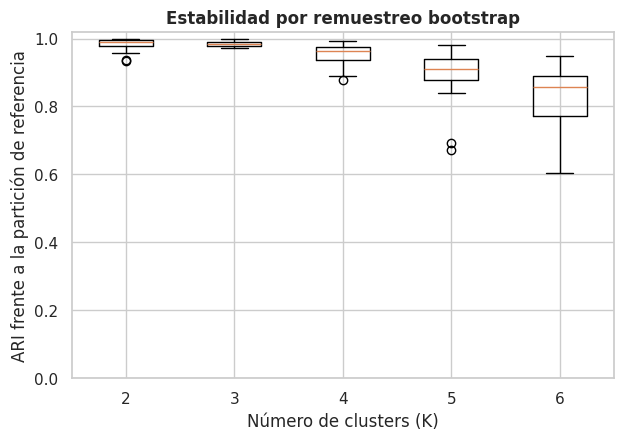


Sin los 38 registros extremos: ARI frente al modelo final = 0.994


In [15]:
stab_rows, boot_store = [], {}
for k in range(2, 7):
    ref = fit_kmeans(X, k).labels_
    ari = seed_stability(X, k, range(10))
    boot = bootstrap_stability(X, k, ref, n_boot=30)
    boot_store[k] = boot
    stab_rows.append({"K": k, "ARI_semillas_media": ari[np.triu_indices(10, 1)].mean(), "ARI_semillas_min": ari[np.triu_indices(10, 1)].min(),
                      "ARI_bootstrap_media": boot.mean(), "ARI_bootstrap_p5": np.percentile(boot, 5)})
stab = pd.DataFrame(stab_rows).set_index("K")
display(stab.round(3))
stab.round(4).to_csv(RES_DIR / "stability.csv")

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.boxplot([boot_store[k] for k in range(2, 7)], tick_labels=list(range(2, 7)))
ax.set(title="Estabilidad por remuestreo bootstrap", xlabel="Número de clusters (K)", ylabel="ARI frente a la partición de referencia")
ax.set_ylim(0, 1.02)
save_fig(fig, "06_estabilidad_bootstrap.png")
plt.show()

mask = ~iqr_outliers(df, CLUSTER_FEATURES).any(axis=1)
prep_wo = Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]).fit(df.loc[mask, CLUSTER_FEATURES])
km_wo = fit_kmeans(prep_wo.transform(df.loc[mask, CLUSTER_FEATURES]), K_FINAL)
pred = km_wo.predict(prep_wo.transform(df[CLUSTER_FEATURES]))
print(f"\nSin los {int((~mask).sum())} registros extremos: ARI frente al modelo final = {adjusted_rand_score(km_raw.labels_, pred):.3f}")

K = 3 es estable: ARI de 1,000 entre semillas y 0,985 por bootstrap. K = 2 también lo es, así que la estabilidad no decide entre 2 y 3; a partir de K = 5 baja. Quitar los 38 registros extremos casi no cambia la partición (ARI 0,994).

## Perfiles

In [16]:
prof_cols = CLUSTER_FEATURES + ["gpa", "stress_score"]
profile_df = X_orig.join(df[["gpa", "stress_score", "stress_level", "field_of_study", "age", "cluster"]])
means = profile_df.groupby("cluster")[prof_cols].mean()
sizes = cluster_sizes(labels)
table_means = means.round(2).join(sizes)
display(table_means)
display(profile_df.groupby("cluster")[prof_cols].median().round(2))
table_means.to_csv(RES_DIR / "cluster_profile_means.csv")
profile_df.groupby("cluster")[prof_cols].median().round(3).to_csv(RES_DIR / "cluster_profile_medians.csv")
es = pd.DataFrame({"eta²": {c: eta_squared(profile_df[c], labels) for c in prof_cols}, "usada en clustering": {c: c in CLUSTER_FEATURES for c in prof_cols}}).round(3)
display(es)
print("V de Cramér cluster-estrés:", round(cramers_v(labels, df["stress_level"]), 3), "| cluster-área de estudio:", round(cramers_v(labels, df["field_of_study"]), 3))

,study_hours,sleep_hours,social_hours,physical_activity_hours,screen_time_hours,extracurricular_hours,gpa,stress_score,n,%
cluster,,,,,,,,,,
A,8.39,5.60,1.07,0.51,2.61,1.00,3.45,7.58,500,33.3
B,5.39,7.55,2.56,1.57,3.04,1.58,3.13,4.03,592,39.5
C,2.98,6.76,4.55,1.02,6.47,0.85,2.56,5.46,408,27.2


,study_hours,sleep_hours,social_hours,physical_activity_hours,screen_time_hours,extracurricular_hours,gpa,stress_score
cluster,,,,,,,,
A,8.4,5.5,1.1,0.5,2.6,1.0,3.45,7.70
B,5.4,7.5,2.6,1.6,3.1,1.6,3.14,3.95
C,2.9,6.8,4.6,1.0,6.5,0.8,2.54,5.40


,eta²,usada en clustering
study_hours,0.800,True
sleep_hours,0.518,True
social_hours,0.735,True
physical_activity_hours,0.436,True
screen_time_hours,0.728,True
extracurricular_hours,0.227,True
gpa,0.627,False
stress_score,0.610,False


V de Cramér cluster-estrés: 0.582 | cluster-área de estudio: 0.062


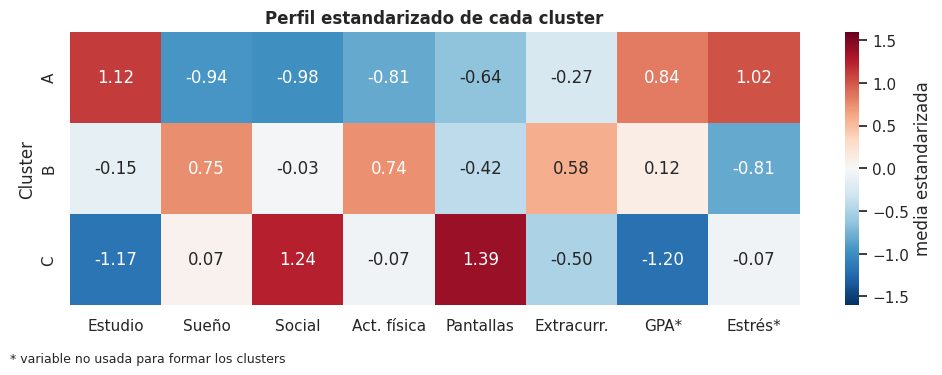

In [17]:
z = pd.DataFrame(X, columns=CLUSTER_FEATURES, index=df.index)
z["gpa"] = StandardScaler().fit_transform(df[["gpa"]]).ravel()
z["stress_score"] = StandardScaler().fit_transform(df[["stress_score"]]).ravel()
zprof = z.groupby(df["cluster"]).mean()
zprof.round(3).to_csv(RES_DIR / "cluster_profile_zscores.csv")
fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(zprof.set_axis(["Estudio", "Sueño", "Social", "Act. física", "Pantallas", "Extracurr.", "GPA*", "Estrés*"], axis=1),
            annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1.6, vmax=1.6, ax=ax, cbar_kws={"label": "media estandarizada"})
ax.set(title="Perfil estandarizado de cada cluster", ylabel="Cluster")
fig.text(0.01, -0.03, "* variable no usada para formar los clusters", fontsize=9)
fig.tight_layout()
save_fig(fig, "07_perfil_estandarizado.png")
plt.show()

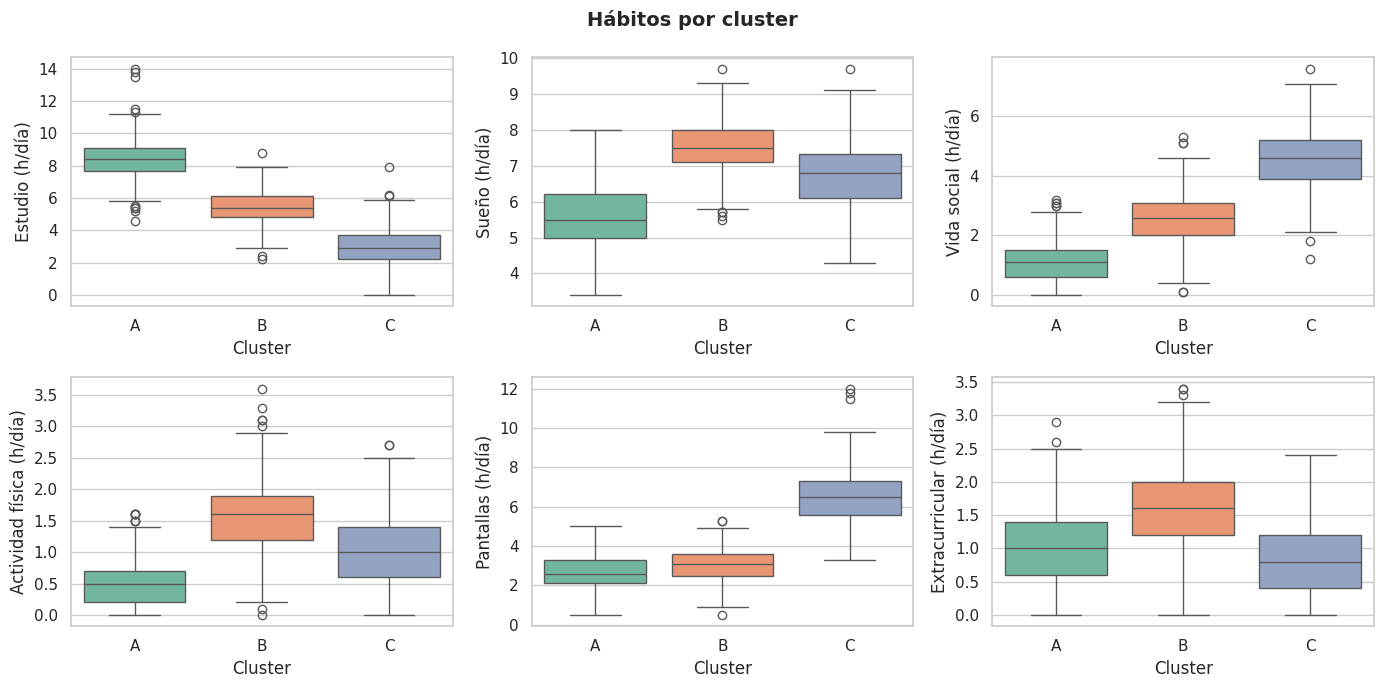

In [18]:
order_c = sorted(df["cluster"].unique())
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
hab_labels = ["Estudio (h/día)", "Sueño (h/día)", "Vida social (h/día)", "Actividad física (h/día)", "Pantallas (h/día)", "Extracurricular (h/día)"]
for ax, c, lab in zip(axes.ravel(), CLUSTER_FEATURES, hab_labels):
    sns.boxplot(data=profile_df, x="cluster", y=c, order=order_c, hue="cluster", hue_order=order_c, legend=False, palette="Set2", ax=ax)
    ax.set(xlabel="Cluster", ylabel=lab)
fig.suptitle("Hábitos por cluster", fontsize=14, fontweight="bold")
fig.tight_layout()
save_fig(fig, "08_habitos_por_cluster.png")
plt.show()

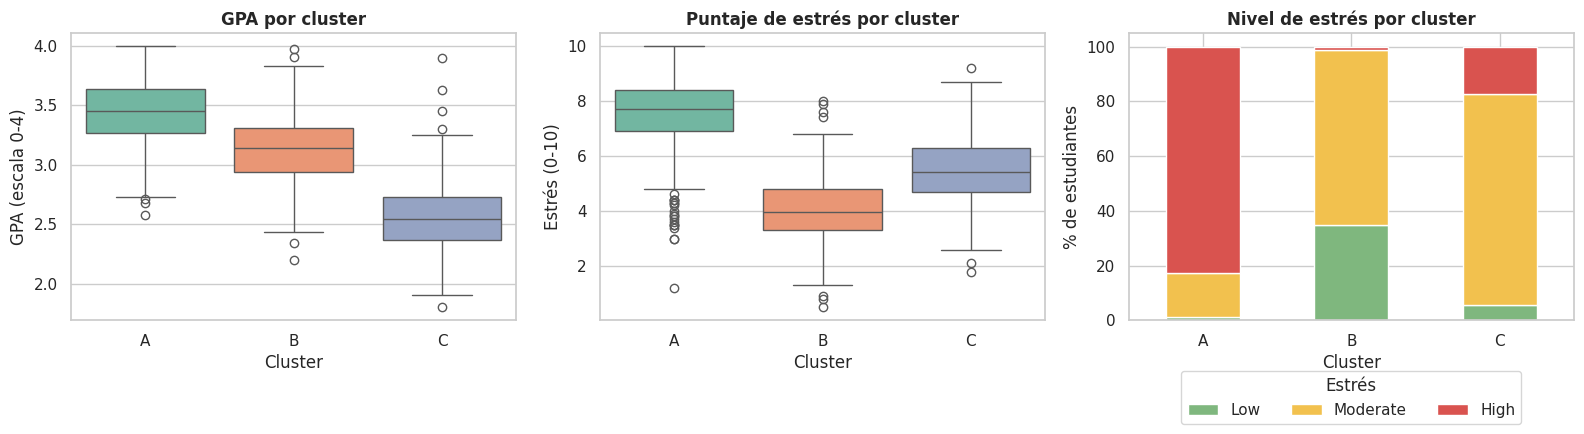

stress_level,Low,Moderate,High
cluster,,,
A,1.4,15.8,82.8
B,34.8,64.0,1.2
C,5.6,77.2,17.2


Kruskal-Wallis GPA: H = 918.6, p = 3.45e-200


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
sns.boxplot(data=profile_df, x="cluster", y="gpa", order=order_c, hue="cluster", hue_order=order_c, legend=False, palette="Set2", ax=axes[0])
axes[0].set(title="GPA por cluster", xlabel="Cluster", ylabel="GPA (escala 0-4)")
sns.boxplot(data=profile_df, x="cluster", y="stress_score", order=order_c, hue="cluster", hue_order=order_c, legend=False, palette="Set2", ax=axes[1])
axes[1].set(title="Puntaje de estrés por cluster", xlabel="Cluster", ylabel="Estrés (0-10)")
stress_pct = pd.crosstab(df["cluster"], df["stress_level"], normalize="index").reindex(columns=STRESS_ORDER) * 100
stress_pct.plot(kind="bar", stacked=True, ax=axes[2], color=["#7fb77e", "#f2c14e", "#d9534f"], rot=0)
axes[2].set(title="Nivel de estrés por cluster", xlabel="Cluster", ylabel="% de estudiantes")
axes[2].legend(title="Estrés", loc="upper center", ncol=3, bbox_to_anchor=(0.5, -0.15))
fig.tight_layout()
save_fig(fig, "09_gpa_estres_por_cluster.png")
plt.show()
display(stress_pct.round(1))
print("Kruskal-Wallis GPA: H = %.1f, p = %.2e" % stats.kruskal(*[df.loc[df.cluster == c, "gpa"] for c in order_c]))

Varianza explicada PC1, PC2: [0.473 0.271] | acumulada: 0.744


,PC1,PC2
study_hours,0.56,0.07
sleep_hours,-0.35,0.42
social_hours,-0.53,-0.17
physical_activity_hours,-0.28,0.54
screen_time_hours,-0.45,-0.42
extracurricular_hours,-0.02,0.57


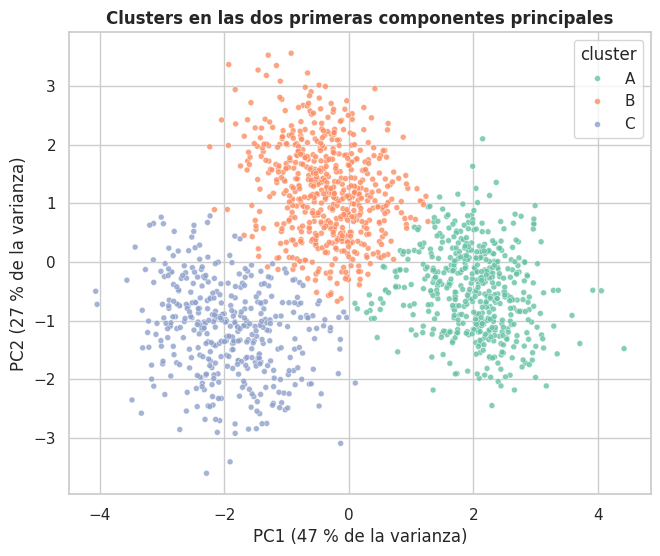

In [20]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
P = pca.transform(X)
print("Varianza explicada PC1, PC2:", pca.explained_variance_ratio_.round(3), "| acumulada:", pca.explained_variance_ratio_.sum().round(3))
display(pd.DataFrame(pca.components_.T, index=CLUSTER_FEATURES, columns=["PC1", "PC2"]).round(2))
fig, ax = plt.subplots(figsize=(7.5, 6))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=df["cluster"], hue_order=order_c, palette="Set2", s=18, alpha=0.8, ax=ax)
ax.set(title="Clusters en las dos primeras componentes principales",
       xlabel=f"PC1 ({100 * pca.explained_variance_ratio_[0]:.0f} % de la varianza)", ylabel=f"PC2 ({100 * pca.explained_variance_ratio_[1]:.0f} % de la varianza)")
save_fig(fig, "10_pca_clusters.png")
plt.show()
pd.DataFrame({ID_COL: df[ID_COL], "cluster": labels}).to_csv(PROC_DIR / "cluster_assignments.csv", index=False)

- **A, sobrecarga académica (33 %).** Estudia 8,4 h y duerme 5,6 h, con poca vida social (1,1 h) y poca actividad física (0,5 h). GPA 3,45 y estrés 7,6; el 83 % tiene estrés alto.
- **B, equilibrado (40 %).** 5,4 h de estudio, 7,6 h de sueño y lo más alto en actividad física (1,6 h) y extracurriculares (1,6 h). GPA 3,13 y estrés 4,0; el 35 % tiene estrés bajo.
- **C, alta distracción digital (27 %).** Estudia 3,0 h, pasa 6,5 h en pantallas y tiene la mayor vida social (4,6 h). GPA 2,56 y estrés 5,5; el 77 % tiene estrés moderado.

Lo que más separa a los grupos es el estudio (eta² 0,80), la vida social (0,74) y las pantallas (0,73). GPA (0,63) y estrés (0,61) también se asocian con los clusters; el área de estudio no (V de Cramér 0,06). El PCA recoge el 74 % de la varianza y se ven tres zonas con algo de solape en los bordes. Son asociaciones, no causas.

## Conclusiones

- Los criterios de selección coinciden en K = 3 y la partición es estable (ARI 0,985 por bootstrap).
- Salen tres perfiles claros: sobrecarga académica, equilibrado y alta distracción digital, con un GPA medio de 3,45, 3,13 y 2,56.
- Estudio, vida social y pantallas son las variables que más separan a los grupos.
- El GPA y el estrés siguen la misma línea que las horas de estudio, pero eso no dice nada sobre causas.